# EDA: детекция дипфейков на фото лиц

Годовой проект №35, магистратура «Искусственный интеллект», НИУ ВШЭ.
Команда: Дмитрий Маслов, Аяз Валиев, Герта Лазовская, Андрей Устамчук. Куратор: Илья Скворцов.

**Как читать.** Здесь собран EDA четырёх датасетов команды. Картинки и таблицы не перерисованы: это сохранённые выводы дочерних ноутбуков из `notebooks/`, под каждой – подпись «Источник». Числа в таблицах – со ссылкой «ноутбук, ячейка» (номер ячейки – индекс с 0). Подробности – в дочерних ноутбуках. Оглавление удобнее открывать в Jupyter или nbviewer.

**Оглавление**
1. [Датасеты и роли](#1.-Датасеты-и-роли)
2. Разделы авторов: [140k](#2.1-140k-Real-and-Fake-Faces) · [OpenForensics](#2.2-OpenForensics,-оригинал-с-Zenodo) · [MFFI](#2.3-MFFI) · [DF40](#2.4-DF40)
3. [Сравнение датасетов](#3.-Сравнение-датасетов)
4. [Общий датасет и сплиты](#4.-Общий-датасет-и-сплиты)
5. [Общие выводы](#5.-Общие-выводы)
6. [Дальнейшие шаги](#6.-Дальнейшие-шаги)
7. [Практическая применимость](#7.-Практическая-применимость)

In [1]:
import base64
import io
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import HTML, Image as ImageOutput, Markdown, display
from PIL import Image

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "notebooks").is_dir())
MIME = {"image": ("image/png", "image/jpeg"), "html": ("text/html",), "text": ("text/plain",)}


def show_output(notebook, cell, n=0, kind="image", max_width=1000, note=None):
    outputs = json.loads((ROOT / "notebooks" / notebook).read_text())["cells"][cell].get("outputs", [])
    if n >= len(outputs):
        raise ValueError(f"{notebook}, ячейка {cell}: выводов {len(outputs)}, нужен вывод {n}")
    data = dict(outputs[n].get("data", {}))
    if outputs[n]["output_type"] == "stream":
        data["text/plain"] = outputs[n]["text"]
    mime = next((m for m in MIME[kind] if m in data), None)
    if mime is None:
        raise ValueError(f"{notebook}, ячейка {cell}, вывод {n}: нет {kind}, есть {sorted(data)}")
    if kind == "image":
        image = Image.open(io.BytesIO(base64.b64decode(data[mime]))).convert("RGB")
        image.thumbnail((max_width, 10 * max_width))
        buffer = io.BytesIO()
        image.save(buffer, format="JPEG", quality=80)
        display(ImageOutput(data=buffer.getvalue(), format="jpeg"))
    elif kind == "html":
        display(HTML("".join(data[mime])))
    else:
        print("".join(data[mime]))
    display(Markdown(f"*Источник: [notebooks/{notebook}](notebooks/{notebook}), ячейка {cell}*"))
    if note:
        display(Markdown(f"*{note}*"))

## 1. Датасеты и роли

| Датасет | Что внутри | Объём | Формат | Роль | Автор | Ноутбук |
| --- | --- | --- | --- | --- | --- | --- |
| 140k Real and Fake Faces | real – FFHQ, fake – StyleGAN, кропы лиц | 140 000 картинок, 70 000 / 70 000 (eda_140k, 7) | JPEG 256×256, q95 (eda_140k, 14) | обучение и проверка шорткатов | Дмитрий Маслов | [eda_140k.ipynb](notebooks/eda_140k.ipynb) |
| OpenForensics, оригинал с Zenodo | фото из жизни, часть лиц подменена; метка стоит на лице | 70 300 кадров, 215 929 лиц: 110 836 real / 105 093 fake (eda_openforensics, 10) | JPEG q100, длинная сторона 1024 у 99% кадров (eda_openforensics, 160) | подмена лиц на фото из жизни | Андрей Устамчук | [eda_openforensics.ipynb](notebooks/eda_openforensics.ipynb) |
| MFFI | 50 методов подделки (по тексту автора, eda_mffi, 1); разобран только обычный Test | 181 947: 77 602 real / 104 345 fake (eda_mffi, 6) | JPG, 512×512 у 96,9% проверенных (eda_mffi, 10) | 50 методов подделки, только Test | Герта Лазовская | [eda_mffi.ipynb](notebooks/eda_mffi.ipynb) |
| DF40, подмножество native EFS + FE | 17 native-методов: генерация лица целиком и редактирование (eda_df40, 4) | 100 000: 1 287 real / 98 713 fake (eda_df40, 4) | PNG 87 753 / JPEG 12 247 (eda_df40, 19) | 17 генераторов + общий датасет и сплиты | Аяз Валиев | [eda_df40.ipynb](notebooks/eda_df40.ipynb) |

## 2. Разделы авторов

### 2.1 140k Real and Fake Faces

*Дмитрий Маслов.* 140 000 кропов лиц 256×256: real – FFHQ, fake – StyleGAN; сплиты авторов 100 / 20 / 20 тыс., классы 50/50. Для сравнения в ноутбуке используется подвыборка 10 тыс. Kaggle-кропов OpenForensics – это не оригинал из раздела 2.2.

| Показатель | Значение | Ячейка |
| --- | --- | --- |
| train / valid / test | 100 000 / 20 000 / 20 000, real = fake | 7 |
| формат | JPEG 256×256, q95, без EXIF; AUC размера файла 0,544 | 14 |
| разброс позы и кадрирования, std fake / real | 0,61–0,81 | 35 |
| читер без взгляда на подделку (бустинг): все признаки / лицо | 0,731 / 0,723 | 49 |
| пар почти-копий в 140k / из них fake–fake | 19 556 / 19 539 (сумма строк 140k) | 77 |
| fake с почти-копией в train: valid / test | 32,48% / 31,43% | 81 |
| чистый test, real / fake | 9 996 / 6 381 | 85 |
| поле вокруг лица (медиана), real / fake; квадрат 1,3× не помещается | 1,34 / 1,33; 30,8% / 31,2% | 89, 92 |
| FFT + логрегрессия, чистый test: ROC-AUC / TPR@1% | 0,673 / 0,050 | 100 |
| то же на JPEG 75: ROC-AUC / ложные тревоги с порогом valid | 0,665 / 7,95% | 100 |
| то же на test, подобранном по читеру / на Kaggle-кропах OpenForensics | 0,634 / 0,563 | 106, 100 |
| FFT по направлениям + бустинг, valid | 0,789 | 111 |

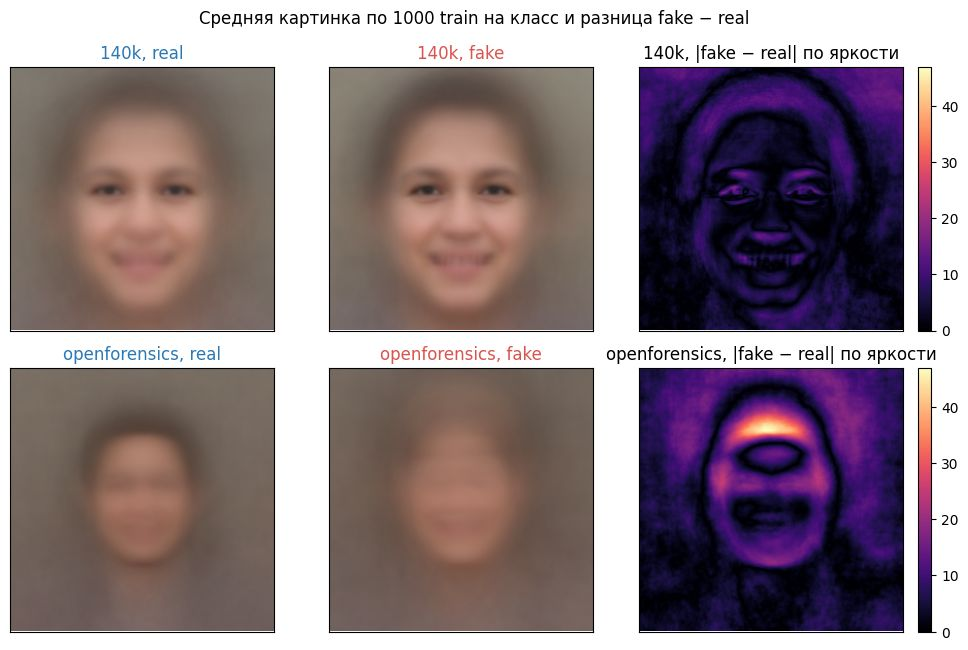

*Источник: [notebooks/eda_140k.ipynb](notebooks/eda_140k.ipynb), ячейка 25*

*Средние лица real и fake чёткие и совпадают по положению: лица выровнены одинаково, разница сосредоточена в чертах лица и яркости фона сверху (раздел 4, «Что видно»).*

In [2]:
show_output("eda_140k.ipynb", 25, n=0, note="Средние лица real и fake чёткие и совпадают по положению: лица выровнены одинаково, разница сосредоточена в чертах лица и яркости фона сверху (раздел 4, «Что видно»).")

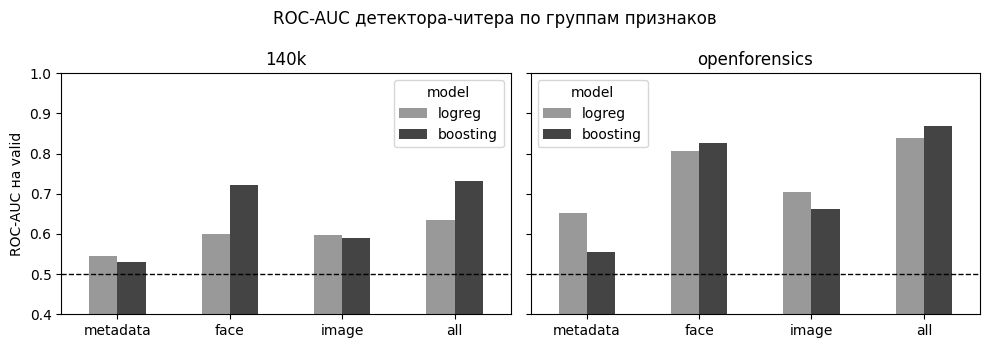

*Источник: [notebooks/eda_140k.ipynb](notebooks/eda_140k.ipynb), ячейка 54*

*ROC-AUC читера по группам признаков вне подделки: real и fake различимы без взгляда на подделку, главный сигнал – положение и поза лица (раздел 6, «Что видно»).*

In [3]:
show_output("eda_140k.ipynb", 54, n=0, note="ROC-AUC читера по группам признаков вне подделки: real и fake различимы без взгляда на подделку, главный сигнал – положение и поза лица (раздел 6, «Что видно»).")

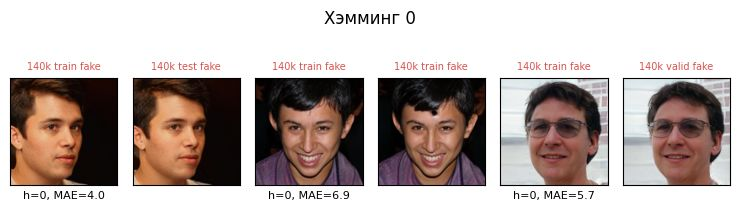

*Источник: [notebooks/eda_140k.ipynb](notebooks/eda_140k.ipynb), ячейка 76*

*Пары-кандидаты по расстоянию Хэмминга: на малых расстояниях – почти одно и то же лицо с мелкими отличиями, генератор выдавал почти-копии (раздел 7).*

In [4]:
show_output("eda_140k.ipynb", 76, n=0, note="Пары-кандидаты по расстоянию Хэмминга: на малых расстояниях – почти одно и то же лицо с мелкими отличиями, генератор выдавал почти-копии (раздел 7).")

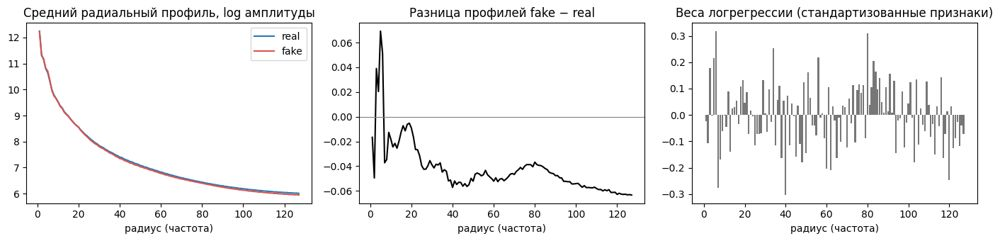

*Источник: [notebooks/eda_140k.ipynb](notebooks/eda_140k.ipynb), ячейка 101*

*Средний профиль, разница fake − real и веса логрегрессии: у fake меньше энергии на средних и высоких частотах – fake «мягче» (раздел 9, «Что видно»).*

In [5]:
show_output("eda_140k.ipynb", 101, n=0, note="Средний профиль, разница fake − real и веса логрегрессии: у fake меньше энергии на средних и высоких частотах – fake «мягче» (раздел 9, «Что видно»).")

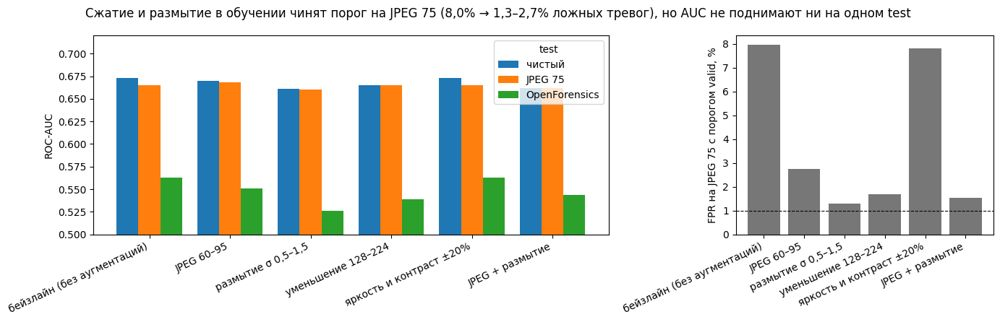

*Источник: [notebooks/eda_140k.ipynb](notebooks/eda_140k.ipynb), ячейка 123*

*Сжатие и уменьшение в обучении почти не меняют AUC, но чинят порог на JPEG 75; разделимость не растёт (раздел 10, «Что видно»).*

In [6]:
show_output("eda_140k.ipynb", 123, n=0, note="Сжатие и уменьшение в обучении почти не меняют AUC, но чинят порог на JPEG 75; разделимость не растёт (раздел 10, «Что видно»).")

**Выводы автора**
1. Технически файлы однородны (JPEG 256×256, q95, без EXIF), класс выдают только имена файлов (раздел 3).
2. Лица выровнены, но у fake разброс позы и положения уже. Читер на признаках вне подделки даёт AUC 0,73 – это планка шортката (разделы 5–6).
3. Почти все почти-копии – у fake (19 539 из 19 556): у 31–32% fake в valid и test есть копия в train. Главные метрики считаем на чистом test, сплиты делим по группам копий (раздел 7).
4. Бейзлайн FFT + логрегрессия слабый (0,673), около пятой части сигнала связано с позой; на незнакомом генераторе – почти наугад (0,563). Спектр по направлениям – кандидат для чекпойнта 3 (раздел 9).
5. Сжатие и уменьшение в обучении удерживают порог (ложные тревоги на JPEG 75 – 1,7–2,7% вместо 8,0%), но разделимость не улучшают (раздел 10).

**Ограничения.** Статистики лица и читер посчитаны на подвыборке 10 000 картинок train+valid, по 5 000 на класс (ячейка 28). Числа получены в окружении `environment.yml`.

Подробно: [notebooks/eda_140k.ipynb](notebooks/eda_140k.ipynb) – разделы 3 «Метаданные», 5 «Статистики лица», 6 «Детектор-читер», 7 «Дубликаты и утечки», 9 «Бейзлайн», 10 «Аугментации».

### 2.2 OpenForensics, оригинал с Zenodo

*Андрей Устамчук.* 70 300 любительских фото (Google Open Images), часть лиц на них заменена сгенерированными; метка стоит на лице, на одном кадре бывают и real, и fake. Сплиты авторов – Train / Val / Test-Dev. Это не Kaggle-кропы OpenForensics из раздела 2.1.

| Показатель | Значение | Ячейка |
| --- | --- | --- |
| кадров Train / Val / Test-Dev | 44 097 / 7 308 / 18 895 | 10 |
| лиц real / fake; доля real по сплитам | 110 836 / 105 093; 56,3% / 31,2% / 42,3% | 10 |
| формат | JPEG q100, без EXIF, длинная сторона 1024 у 99,0–99,3% | 160 |
| точные копии (MD5) / пар копий одного фото | 0 / 25 021 | 160, 23 |
| кадров, у которых есть копия: Train / Val / Test-Dev | 69,8% / 74,6% / 73,1% | 23 |
| утечки между сплитами (та же сцена или человек) | 0,06% / 0,12% / 0,12% кадров | 26 |
| одно лицо размечено и real, и fake | 73 пары, 146 лиц | 58 |
| рамка fake меньше рамки того же лица в real | 95,4% из 16 669 пар | 46 |
| FFT + логрегрессия, Val / Test-Dev: AUC; TPR@1% | 0,836 / 0,854; 0,026 / 0,043 | 126 |
| дообученная ResNet-18, Val / Test-Dev: AUC; TPR@1% | 0,995 / 0,998; 0,903 / 0,957 | 136 |

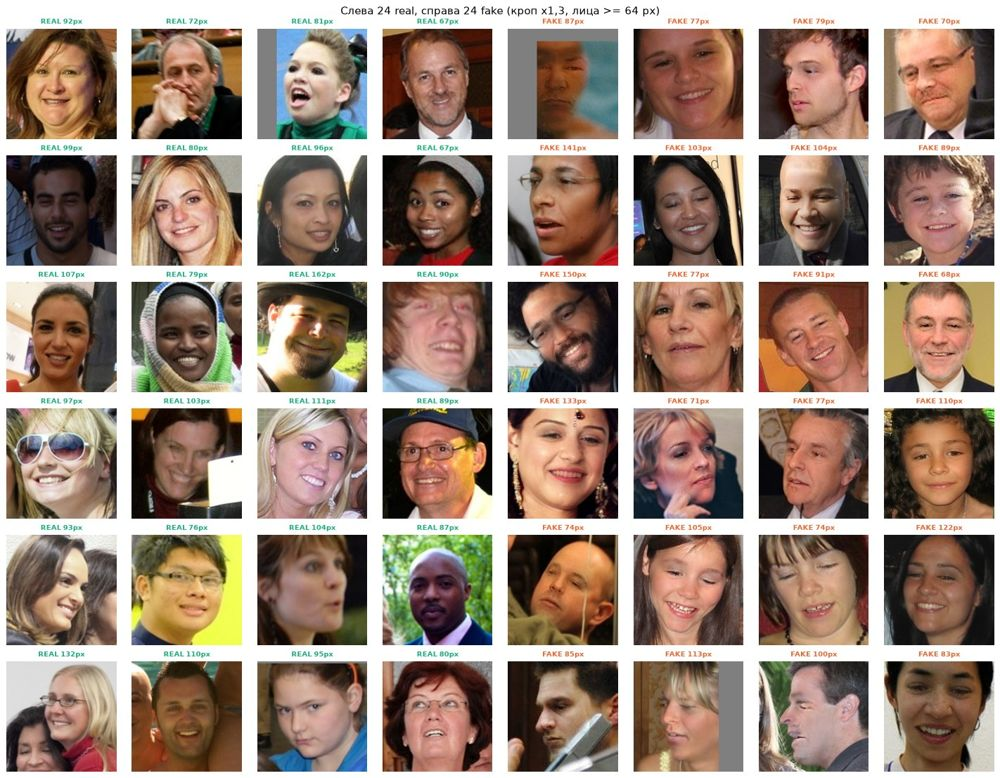

*Источник: [notebooks/eda_openforensics.ipynb](notebooks/eda_openforensics.ipynb), ячейка 62*

*Кропы real и fake: часть fake выдаёт «восковая» кожа и мягкость лица, но многие выглядят естественно – глазами задача трудная (ячейка 65).*

In [7]:
show_output("eda_openforensics.ipynb", 62, note="Кропы real и fake: часть fake выдаёт «восковая» кожа и мягкость лица, но многие выглядят естественно – глазами задача трудная (ячейка 65).")

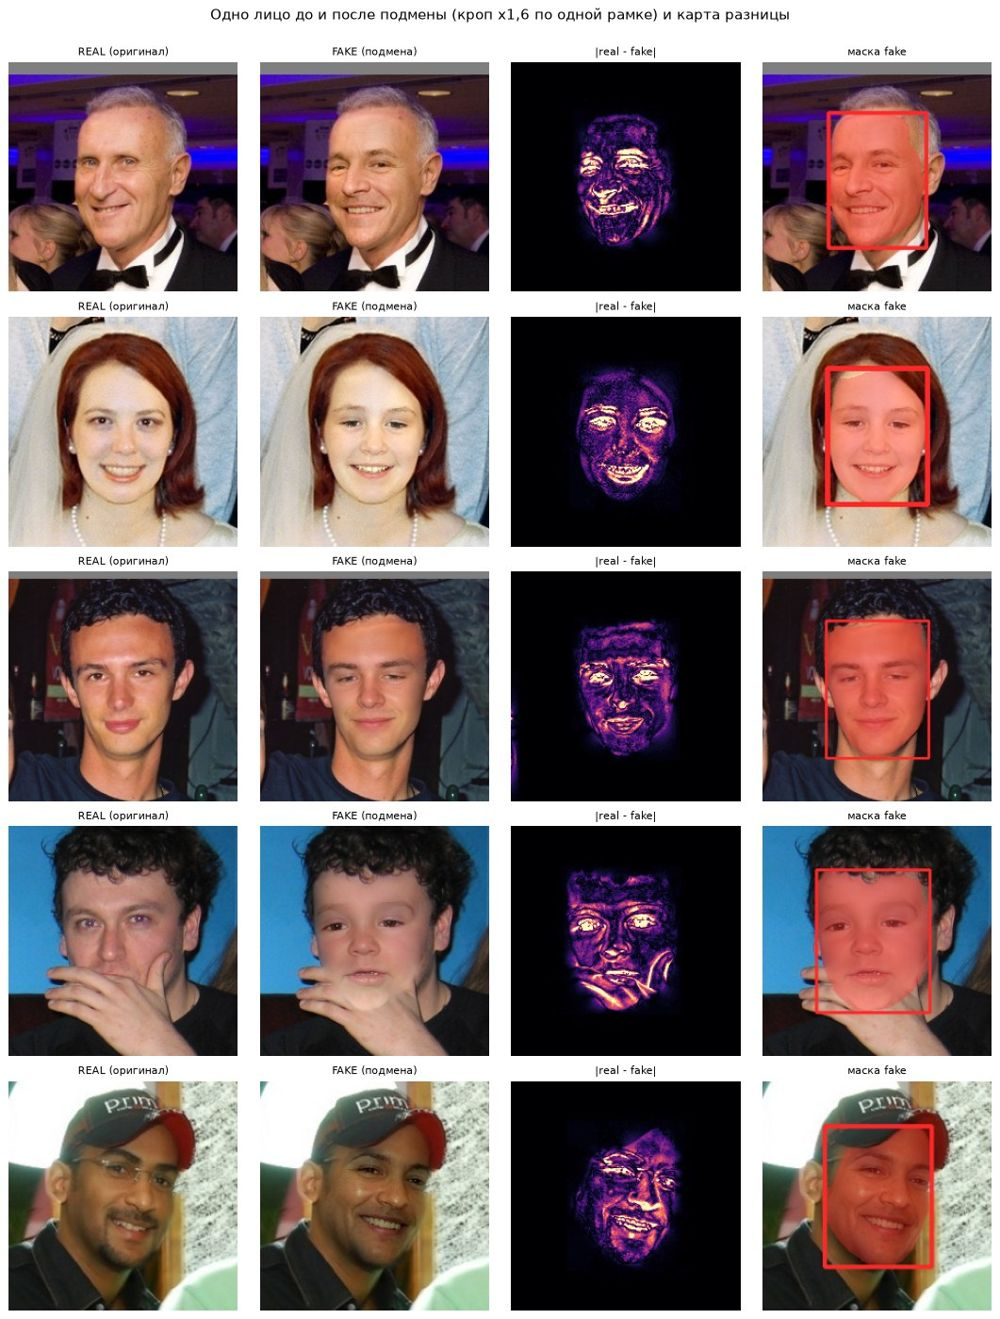

*Источник: [notebooks/eda_openforensics.ipynb](notebooks/eda_openforensics.ipynb), ячейка 67*

*Одно лицо до и после подмены: карта разницы светится только внутри маски – генератор меняет черты лица, а поза, причёска, свет и фон остаются (ячейка 68).*

In [8]:
show_output("eda_openforensics.ipynb", 67, note="Одно лицо до и после подмены: карта разницы светится только внутри маски – генератор меняет черты лица, а поза, причёска, свет и фон остаются (ячейка 68).")

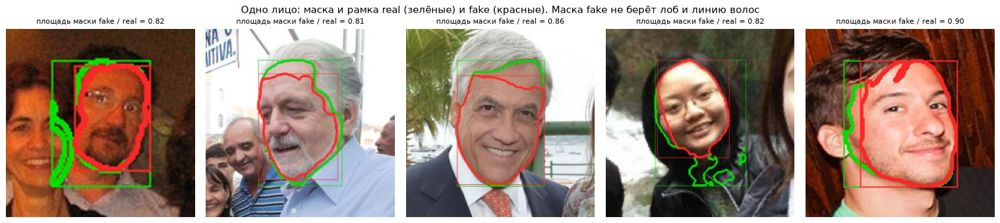

*Источник: [notebooks/eda_openforensics.ipynb](notebooks/eda_openforensics.ipynb), ячейка 47*

*Зелёный контур – разметка real, красный – fake того же лица: маска fake обводит только нарисованную область без лба, поэтому рамка fake теснее (ячейка 48).*

In [9]:
show_output("eda_openforensics.ipynb", 47, note="Зелёный контур – разметка real, красный – fake того же лица: маска fake обводит только нарисованную область без лба, поэтому рамка fake теснее (ячейка 48).")

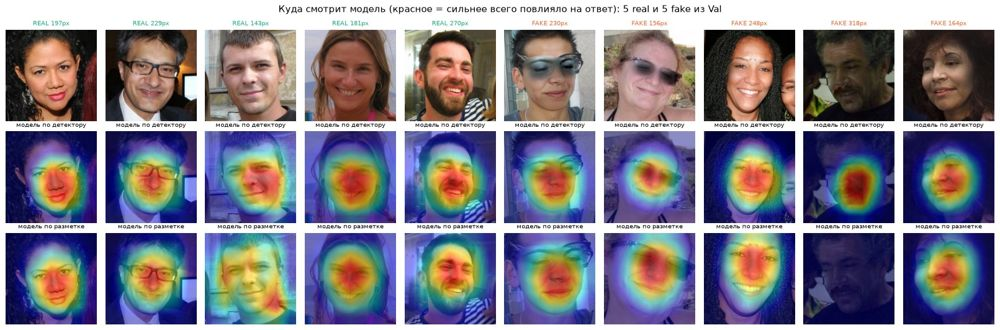

*Источник: [notebooks/eda_openforensics.ipynb](notebooks/eda_openforensics.ipynb), ячейка 146*

*Grad-CAM: красная зона почти всегда в центре лица, а не на фоне и не на соседях – модель смотрит на лицо (ячейка 147).*

In [10]:
show_output("eda_openforensics.ipynb", 146, note="Grad-CAM: красная зона почти всегда в центре лица, а не на фоне и не на соседях – модель смотрит на лицо (ячейка 147).")

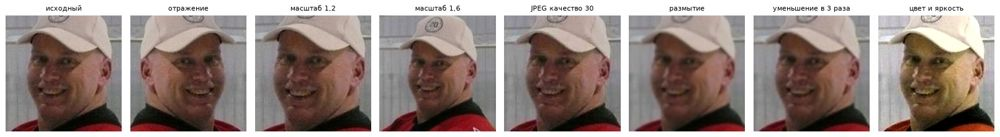

*Источник: [notebooks/eda_openforensics.ipynb](notebooks/eda_openforensics.ipynb), ячейка 152*

*Так выглядят искажения при обучении на одном лице; на сжатых и уменьшенных кропах они сильнее всего меняют качество (ячейки 151, 154).*

In [11]:
show_output("eda_openforensics.ipynb", 152, note="Так выглядят искажения при обучении на одном лице; на сжатых и уменьшенных кропах они сильнее всего меняют качество (ячейки 151, 154).")

In [12]:
show_output("eda_openforensics.ipynb", 156, kind="html")

*Источник: [notebooks/eda_openforensics.ipynb](notebooks/eda_openforensics.ipynb), ячейка 156*

**Выводы автора**
1. «Данным можно доверять»: формат у всех кадров один, одних и тех же фото в разных сплитах нет. Но копии одного фото лежат внутри Train у 70% кадров, поэтому Train делим по `source_id` (ячейки 24, 28, 157).
2. Real и fake различаются не только подделкой: fake чаще взяты из фото на двоих, чаще в полупрофиль и чуть светлее – это отбор лиц для подмены, а не след генератора (ячейки 103, 157).
3. «Разметка сама подсказывает ответ»: рамка fake теснее, сеть этим пользуется, поэтому кропы режутся только по детектору лиц (ячейки 48, 143, 157).
4. Внутри OpenForensics задача для нейросети почти решена: 0,995 / 0,998 описывает один генератор 2021 года (ячейки 137, 157).
5. Модель слабее на крупных и тёмных лицах; без аугментаций сжатие отнимает треть пойманных подделок, базовый набор – отражение + JPEG + масштаб + размытие (ячейки 140, 154, 157).

**Ограничения.** Сохранённые выводы – с прошлого прогона, графики в ячейках 20, 105, 109 не сохранились. Модели раздела 8 читаются из кэша `results/`, обучение – на подвыборке (ячейка 120).

Подробно: [notebooks/eda_openforensics.ipynb](notebooks/eda_openforensics.ipynb) – разделы 2 «Копии и утечки», 3 «Разметка», 6 «Выбросы», 8 «Бейзлайн и аугментации», A1 «Файлы кадров».

### 2.3 MFFI

*Герта Лазовская.* MFFI – датасет подделок в условиях, близких к реальным: по тексту автора, более 1 млн изображений и 50 методов подделки (ячейка 1). Разобран только обычный Test (phase2); метки – бинарные, без метода подделки.

| Показатель | Значение | Ячейка |
| --- | --- | --- |
| Test, real / fake | 77 602 / 104 345 (fake 57,35%) | 6, 16 |
| размер 512×512 в проверке 10 000 файлов | 9 694 (96,9%) | 10 |
| битые файлы в проверке 10 000 | 0 | 10 |
| кандидаты dHash в подвыборке 5 000 | 38 групп, 80 изображений (1,60%) | 12, 16 |
| LogReg на пикселях 64×64, 2 000 картинок (1 600 / 400) | accuracy 0,6175 | 15, 16 |

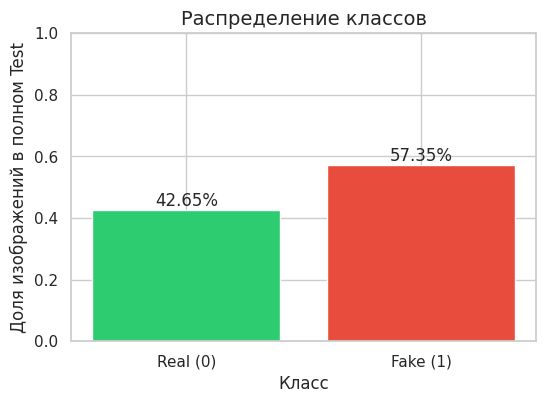

*Источник: [notebooks/eda_mffi.ipynb](notebooks/eda_mffi.ipynb), ячейка 6*

*Баланс классов во всём Test: fake больше, чем real (ячейка 6).*

In [13]:
show_output("eda_mffi.ipynb", 6, n=1, note="Баланс классов во всём Test: fake больше, чем real (ячейка 6).")

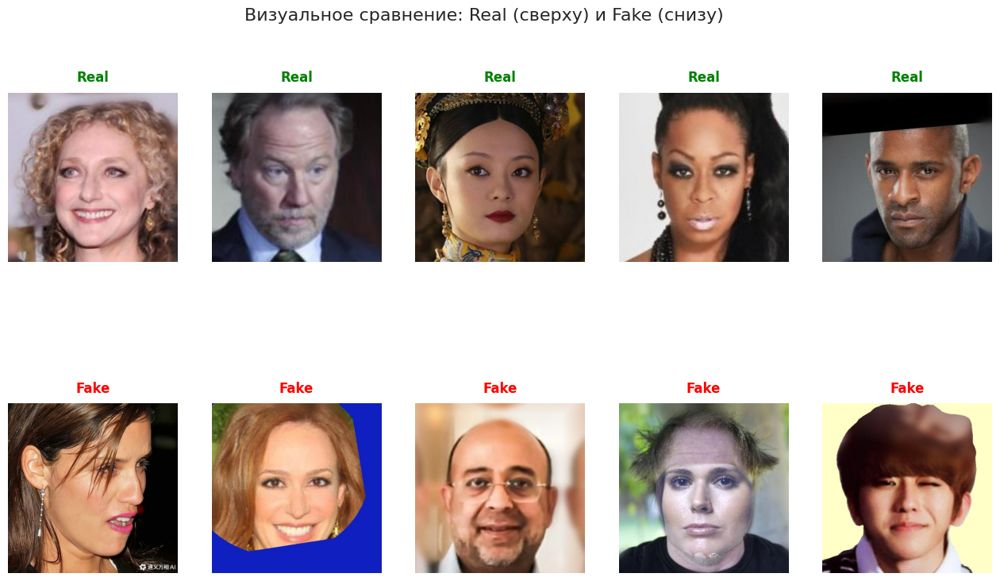

*Источник: [notebooks/eda_mffi.ipynb](notebooks/eda_mffi.ipynb), ячейка 8*

*Примеры real (сверху) и fake (снизу): в MFFI разные типы атак, поэтому и артефакты разные (ячейка 7).*

In [14]:
show_output("eda_mffi.ipynb", 8, note="Примеры real (сверху) и fake (снизу): в MFFI разные типы атак, поэтому и артефакты разные (ячейка 7).")

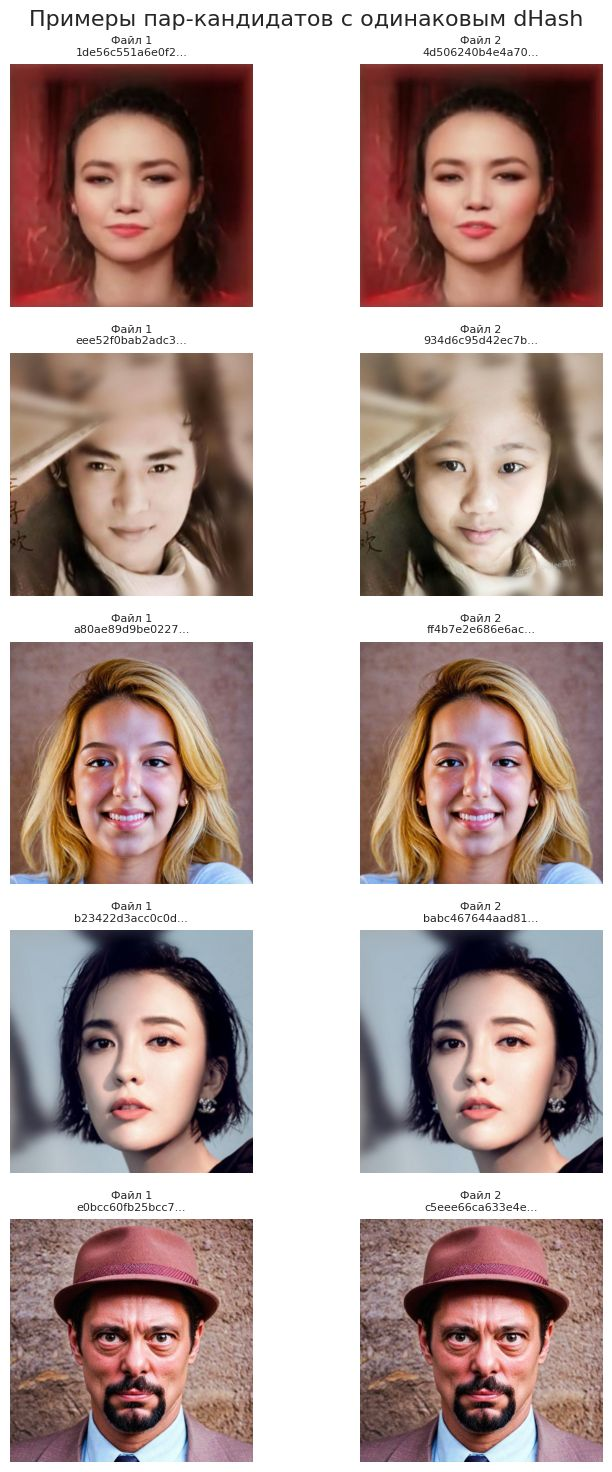

*Источник: [notebooks/eda_mffi.ipynb](notebooks/eda_mffi.ipynb), ячейка 13*

*Пары-кандидаты с одинаковым dHash: визуально похожие изображения; точную копию это не подтверждает (ячейка 11).*

In [15]:
show_output("eda_mffi.ipynb", 13, note="Пары-кандидаты с одинаковым dHash: визуально похожие изображения; точную копию это не подтверждает (ячейка 11).")

**Выводы автора** (ячейка 16)
1. Во всём обычном Test 181 947 изображений: real 42,65%, fake 57,35%.
2. Проверка декодирования охватила 10 000 файлов, не прочиталось 0.
3. dHash: 38 групп кандидатов, 80 изображений (1,60% подвыборки); совпадение dHash не подтверждает точную копию.
4. Logistic Regression: accuracy 0,6175 на случайном split небольшой подвыборки Test; кандидаты dHash перед этим не удалялись.
5. Типы генераторов и манипуляций нельзя восстановить из бинарного файла меток.

**Ограничения.** Только Test; пиксельный анализ – на подвыборке 20 000; кандидаты dHash не подтверждены; бейзлайн – accuracy 0,6175 на 400 картинках при доле fake 57,4% во всём Test; меток генератора в Test нет.

Подробно: [notebooks/eda_mffi.ipynb](notebooks/eda_mffi.ipynb) – разделы 2 «Баланс классов», 4 «Проверка целостности», 5 «Кандидаты на похожие изображения», 6 «Бейзлайн».

### 2.4 DF40

*Аяз Валиев.* Подмножество DF40 native EFS + FE: генерация лица целиком и редактирование, 17 native-методов, 100 000 изображений. Тот же ноутбук собирает общий датасет и сплиты (раздел 4).

| Показатель | Значение | Ячейка |
| --- | --- | --- |
| native-инвентарь / выборка | 619 733 / 100 000 изображений | 4 |
| real / fake в выборке | 1 287 / 98 713 (fake 98,7%) | 4 |
| формат | PNG 87 753 – только fake; JPEG 12 247 (10 960 fake + 1 287 real) | 17, 19 |
| качество JPEG | fake: q75 – 10 799, q100 – 161, PNG – 87 753; real: q95 у 161 из 1 287, всего 3 уровня (n=0); уровни real по отдельности в выводе обрезаны | 19 |
| без лица (YuNet) | 769 из 100 000 | 13 |
| покрытие YuNet: native + уменьшенная копия / только native | 0,992 / 0,784 | 9 |
| кроп 1,3 × bbox хотя бы частично за краем | 86,1% | 13 |
| пригодно после исключений | 98 020 | 4, 23 |

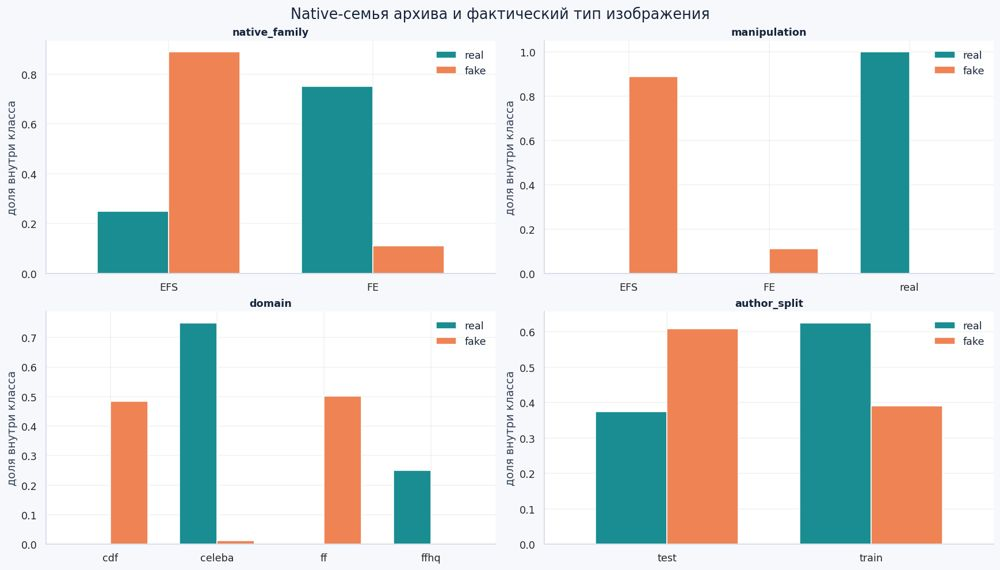

*Источник: [notebooks/eda_df40.ipynb](notebooks/eda_df40.ipynb), ячейка 7*

*Состав выборки по native-семье, типу манипуляции, домену и авторскому сплиту: пропорции real/fake повторяют native-инвентарь, 50/50 не навязывается (ячейка 3).*

In [16]:
show_output("eda_df40.ipynb", 7, n=1, note="Состав выборки по native-семье, типу манипуляции, домену и авторскому сплиту: пропорции real/fake повторяют native-инвентарь, 50/50 не навязывается (ячейка 3).")

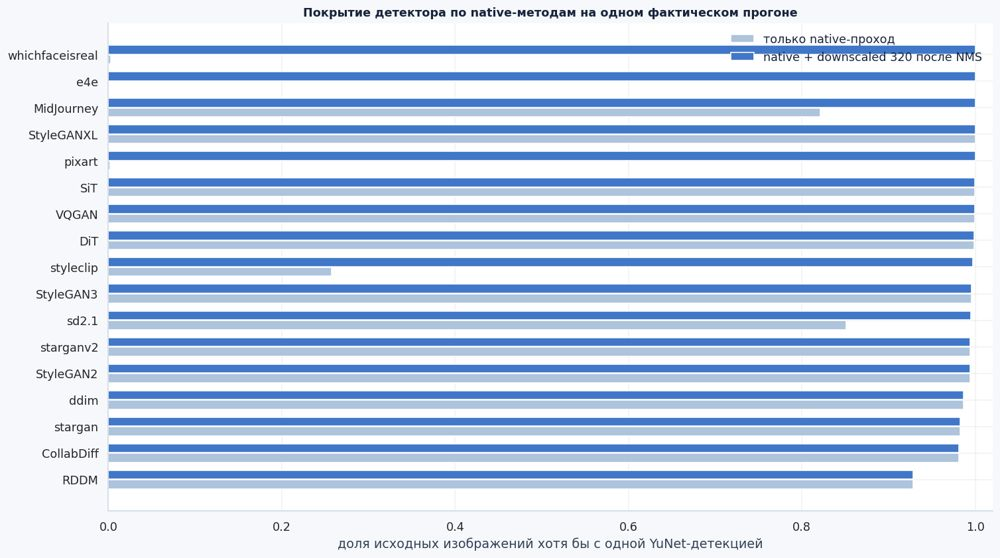

*Источник: [notebooks/eda_df40.ipynb](notebooks/eda_df40.ipynb), ячейка 9*

*Покрытие YuNet по native-методам: без прохода на уменьшенной копии почти теряются e4e и pixart, с ним покрытие близко к полному (ячейки 8, 9).*

In [17]:
show_output("eda_df40.ipynb", 9, n=2, note="Покрытие YuNet по native-методам: без прохода на уменьшенной копии почти теряются e4e и pixart, с ним покрытие близко к полному (ячейки 8, 9).")

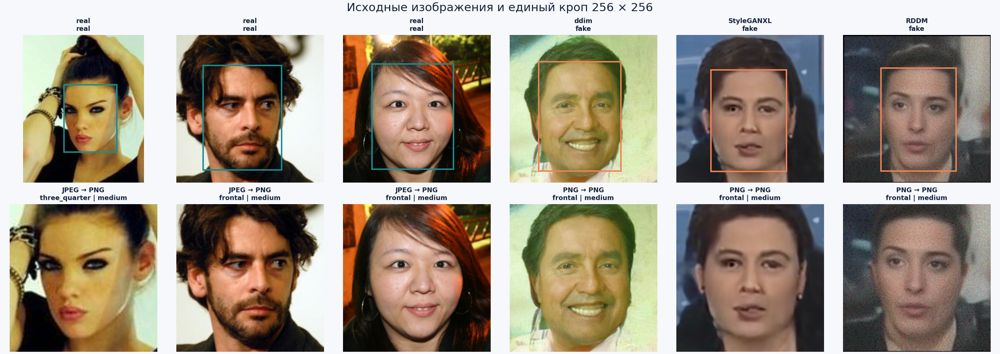

*Источник: [notebooks/eda_df40.ipynb](notebooks/eda_df40.ipynb), ячейка 11*

*Исходники и единый кроп 256×256: real – JPEG, fake – в основном PNG; иллюстрации из предыдущего pixel-прогона (ячейки 10, 11).*

In [18]:
show_output("eda_df40.ipynb", 11, n=1, note="Исходники и единый кроп 256×256: real – JPEG, fake – в основном PNG; иллюстрации из предыдущего pixel-прогона (ячейки 10, 11).")

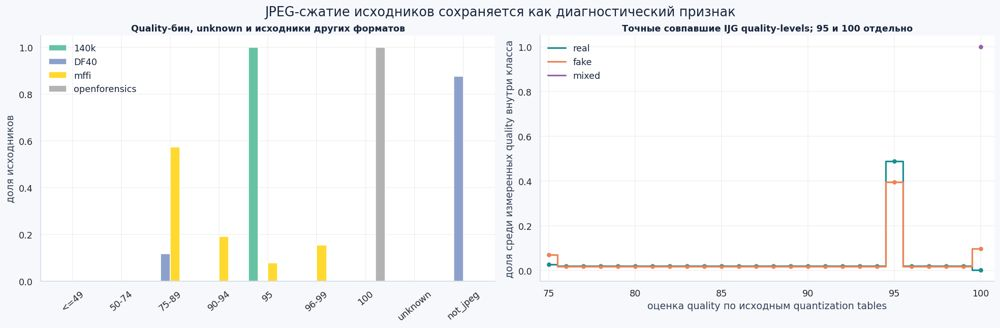

*Источник: [notebooks/eda_df40.ipynb](notebooks/eda_df40.ipynb), ячейка 19*

*Качество JPEG по исходным таблицам квантования: у каждого датасета своё, автор сохраняет его как диагностический признак, 95 и 100 – отдельно (ячейка 18).*

In [19]:
show_output("eda_df40.ipynb", 19, n=2, note="Качество JPEG по исходным таблицам квантования: у каждого датасета своё, автор сохраняет его как диагностический признак, 95 и 100 – отдельно (ячейка 18).")

**Выводы автора**
1. Баланс real/fake повторяет пропорции native-инвентаря, 50/50 не навязывается (ячейка 3); фактически fake – 98,7% (ячейка 4).
2. Для крупных лиц YuNet нужен дополнительный проход на уменьшенной копии: покрытие 0,992 против 0,784 у одного native-прохода (ячейки 8, 9).
3. В выбранном DF40 среди PNG нет real-примеров; разница в размере файла real/fake – возможный датасетный биас (ячейки 17, 18).
4. Общий сплит глобальный, 70 / 15 / 15 по подтверждённым группам копий; авторские сплиты остаются метаданными (ячейка 24).
5. Пересечений по группам и хешам между частями нет, но полную независимость по личности без её разметки подтвердить нельзя (ячейки 38, 40).

**Ограничения.** В выборке 98,7% fake; сравнение с авторским разбиением не подготовлено (ячейки 33, 42); часть иллюстраций – из предыдущего прогона (ячейки 11, 16).

Подробно: [notebooks/eda_df40.ipynb](notebooks/eda_df40.ipynb) – разделы 2 «Что именно выбрали», 4 «Квадрат 1,3 × bbox», 5 «Геометрия, формат и качество», 11 «Проверка утечек», 12 «Полные композитные сплиты».

## 3. Сравнение датасетов

### 3.1 Баланс классов

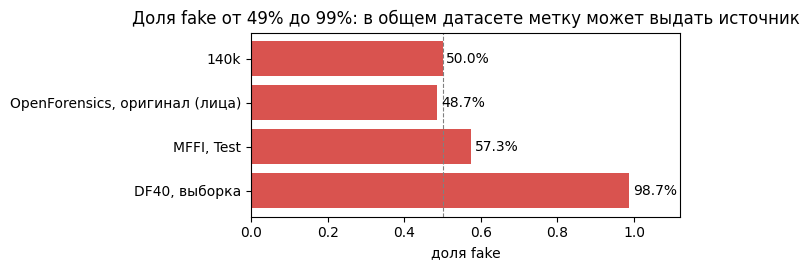

,датасет,fake,всего,источник,доля fake
0,140k,"70,000","140,000","eda_140k, 7",50.0%
1,"OpenForensics, оригинал (лица)","105,093","215,929","eda_openforensics, 10",48.7%
2,"MFFI, Test","104,345","181,947","eda_mffi, 6",57.3%
3,"DF40, выборка","98,713","100,000","eda_df40, 4",98.7%


In [20]:
fake_share = pd.DataFrame([
    ("140k", 70_000, 140_000, "eda_140k, 7"),
    ("OpenForensics, оригинал (лица)", 105_093, 215_929, "eda_openforensics, 10"),
    ("MFFI, Test", 104_345, 181_947, "eda_mffi, 6"),
    ("DF40, выборка", 98_713, 100_000, "eda_df40, 4"),
], columns=["датасет", "fake", "всего", "источник"])
fake_share["доля fake"] = fake_share["fake"] / fake_share["всего"]

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(fake_share["датасет"], fake_share["доля fake"], color="#d9534f")
ax.axvline(0.5, color="grey", linestyle="--", linewidth=0.8)
for y, share in enumerate(fake_share["доля fake"]):
    ax.text(share + 0.01, y, f"{share:.1%}", va="center")
ax.set_xlim(0, 1.12)
ax.invert_yaxis()
ax.set_xlabel("доля fake")
ax.set_title("Доля fake от 49% до 99%: в общем датасете метку может выдать источник")
fig.tight_layout()
plt.show()
fake_share.style.format({"доля fake": "{:.1%}", "fake": "{:,}", "всего": "{:,}"})

**Вывод.** Доля fake сильно зависит от датасета: около половины в 140k и OpenForensics, 57% в MFFI, 99% в DF40. В общем датасете модель может угадывать метку по источнику, а не по подделке – это нужно проверять отдельно.

### 3.2 Ошибки и качество

| Датасет | Копии | Утечки между сплитами | Противоречивая разметка | Битые файлы |
| --- | --- | --- | --- | --- |
| 140k | точных 0; 19 556 пар почти-копий (eda_140k, 77) | fake с копией в train: 32,48% valid, 31,43% test (eda_140k, 81) | – | все файлы открываются (eda_140k, 14); заголовки всех 140 000 прочитаны (eda_df40, 19) |
| OpenForensics, оригинал | MD5 0 (eda_openforensics, 160); 25 021 пара копий одного фото (eda_openforensics, 23) | точных 0 (eda_openforensics, 23); та же сцена или человек – 0,06–0,12% кадров (eda_openforensics, 26) | 73 пары «одно лицо real и fake» (eda_openforensics, 58) | 0, все читаются (eda_openforensics, 160) |
| MFFI | кандидаты dHash – 1,60% подвыборки 5 000 (eda_mffi, 16) | – (только Test) | – | 0 из 10 000 (eda_mffi, 10) |
| DF40 | 2 943 повторяющихся SHA изображения (eda_df40, 23) | в общем датасете 0 по группам и хешам (eda_df40, 39, 42) | конфликтов меток по SHA кропа 0 (eda_df40, 39) | ошибок декодирования 0 (eda_df40, 13) |

### 3.3 Выбросы

| Датасет | Мелкие лица | Без лица | Профили | Нестандартные разрешения |
| --- | --- | --- | --- | --- |
| 140k | – (сторона рамки YuNet, медиана 190–192 px из 256, eda_140k, 89) | 104 из 140 000 (eda_df40, 14) | – | нет, все 256×256 (eda_140k, 14) |
| OpenForensics, оригинал | среди лиц < 32 px YuNet находит 28–78% (eda_openforensics, 55) | ни один детектор не нашёл 49 из 159 172 крупных лиц, 0,03% (eda_openforensics, 91) | профиль > 45°: 0,6–1,4% лиц (eda_openforensics, 105) | длинная сторона 1024 у 99,0–99,3%, максимум 7 360 (eda_openforensics, 160) |
| MFFI | – | 4 135 из 181 947 (eda_df40, 14) | – | 3,1% проверенных не 512×512 (eda_mffi, 10) |
| DF40 | – | 769 из 100 000 (eda_df40, 13) | – | квадратных 99,7% (eda_df40, 13) |

### 3.4 Шорткаты

| Датасет | Шорткат | Число | Ячейка |
| --- | --- | --- | --- |
| 140k | поза и кадрирование: читер без взгляда на подделку | AUC 0,731 (бустинг, все признаки) | eda_140k, 49 |
| OpenForensics, оригинал | крупность лица в кропе по разметке | AUC 0,817–0,849 | eda_openforensics, 142 |
| DF40 | PNG только у fake: 12 генераторов – 100% PNG, real – 100% JPEG | – | eda_df40, 17 |
| общий датасет | доля fake по источникам 49–99%; качество JPEG: 140k – q95, OpenForensics – q100, MFFI – 25 разных таблиц квантования | см. 3.1 | eda_df40, 19 |

### 3.5 Бейзлайны

Протоколы разные (выборки, метрики, кропы), поэтому числа между датасетами не сравнимы.

| Датасет | Модель | Протокол | Результат |
| --- | --- | --- | --- |
| 140k | радиальный FFT + логрегрессия | train 17 188 (без почти-копий, баланс по позе), чистый test 9 996 / 6 381; ROC-AUC, TPR@1% | 0,673 / 0,050 (eda_140k, 99, 100) |
| Kaggle-кропы OpenForensics | та же модель, обученная на 140k | перенос на незнакомый генератор, ROC-AUC | 0,563 (eda_140k, 100) |
| OpenForensics, оригинал | FFT + логрегрессия | подвыборка Train 8 514 / 8 514, кроп по детектору; Val / Test-Dev, AUC | 0,836 / 0,854 (eda_openforensics, 120, 126) |
| OpenForensics, оригинал | дообученная ResNet-18 | то же; AUC, TPR@1% | 0,995 / 0,998; 0,903 / 0,957 (eda_openforensics, 136) |
| MFFI | LogReg на пикселях 64×64 | 2 000 картинок Test, случайный split 1 600 / 400; accuracy | 0,6175 (eda_mffi, 15) |
| DF40 | – | – | – |

### 3.6 Аугментации

| Датасет | Что проверяли | Результат | Ячейка |
| --- | --- | --- | --- |
| 140k | бейзлайн FFT, по одной аугментации: JPEG 60–95, размытие, уменьшение, яркость и контраст, JPEG + размытие | AUC на чистом test 0,661–0,673; ложные тревоги на JPEG 75: 7,95% → 1,30–2,74%; AUC на Kaggle-кропах OpenForensics 0,526–0,563 – не растёт | eda_140k, 122 |
| OpenForensics, оригинал | ResNet-18, 5 конфигураций × 2 seed | TPR@1% на JPEG 50: 0,60 / 0,64 → 0,82 / 0,86 (+ JPEG + масштаб); на уменьшенных вдвое: 0,68 / 0,73 → 0,89 / 0,91 (+ размытие) | eda_openforensics, 153 |

## 4. Общий датасет и сплиты

*Аяз Валиев.* Общий датасет из четырёх источников: глобальный сплит 70 / 15 / 15 по подтверждённым группам копий (ячейка 24). Почти-копии – pHash, затем проверка пикселями.

| Показатель | Значение | Ячейка |
| --- | --- | --- |
| исходных изображений: DF40 / 140k / OpenForensics / MFFI | 100 000 / 140 000 / 70 300 / 181 947 | 42 |
| train / validate / test, лиц | 395 329 / 84 713 / 84 713 | 42 |
| исключено строк обработки | 75 537 | 42 |
| пар-кандидатов почти-копий / подтверждено | 275 969 / 80 311 | 42 |
| пересечения между сплитами по группам и хешам | 0 | 39 (demo), 42 (full) |

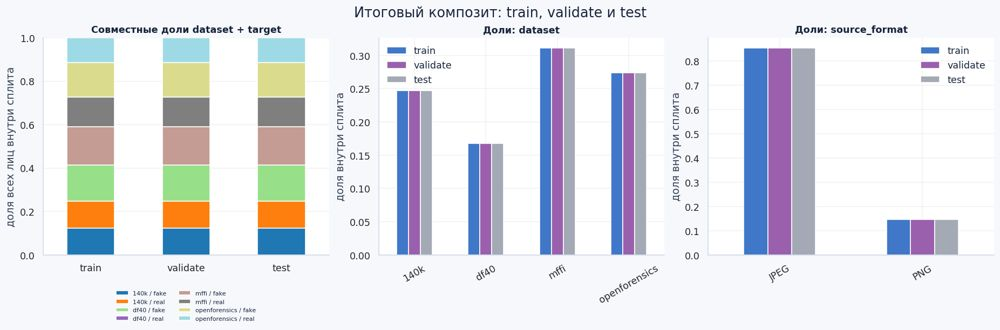

*Источник: [notebooks/eda_df40.ipynb](notebooks/eda_df40.ipynb), ячейка 42*

*Итоговый композит: доли источников, классов и форматов одинаковы в train, validate и test (раздел 12).*

In [21]:
show_output("eda_df40.ipynb", 42, n=2, note="Итоговый композит: доли источников, классов и форматов одинаковы в train, validate и test (раздел 12).")

In [22]:
show_output("eda_df40.ipynb", 39, n=0, kind="html")

,групп,между сплитами,без ключа
ключ,,,
group_id,75505,0,0
image_sha256,77307,0,0
decoded_sha256,77307,0,0
crop_sha256,107079,0,0


*Источник: [notebooks/eda_df40.ipynb](notebooks/eda_df40.ipynb), ячейка 39*

Таблица пересечений выше – для demo (20k исходников на источник); для полного композита те же нули (eda_df40, ячейка 42).

## 5. Общие выводы

1. Данные технически чистые: файлы читаются, битых нет (140k – все файлы открываются, eda_140k, 14, и заголовки всех 140 000 прочитаны, eda_df40, 19; eda_openforensics, 160; eda_mffi, 10; eda_df40, 13). Но в каждом датасете свой шорткат: поза и кадрирование (140k, читер 0,731), рамка разметки (OpenForensics, 0,817–0,849), формат PNG (DF40), источник (общий датасет, доля fake 49–99%).
2. Копии одного фото – главный источник утечек: в 140k у 31–32% fake в valid и test есть копия в train, в OpenForensics копия есть у 70–75% кадров внутри сплитов. Делить данные – только по группам копий.
3. Внутри одного датасета задача решается (OpenForensics, ResNet-18 – AUC 0,995), простые признаки слабее (FFT – 0,673 на 140k, 0,836–0,854 на OpenForensics), а перенос на чужой генератор почти наугад (FFT с 140k на Kaggle-кропах OpenForensics – 0,563).
4. Сжатие сбивает порог (140k: 7,95% ложных тревог на JPEG 75 вместо 1%) и снижает долю пойманных подделок (OpenForensics: TPR@1% 0,60 / 0,64 на JPEG 50); аугментации JPEG + масштаб это исправляют.
5. Качество неравномерно по группам лиц: на OpenForensics TPR@1% на Val – 0,737 у тёмных лиц против 0,912–0,925 у лиц средней светлоты и 0,826 у крупных (≥ 256 px) против 0,908–0,978 у лиц 64–256 px (eda_openforensics, 139); профилей > 45° всего 0,6–1,4% лиц (eda_openforensics, 105).
6. Метрики и протоколы у всех разные (ROC-AUC, TPR@1%, accuracy; разные выборки и кропы) – нужен единый протокол.

## 6. Дальнейшие шаги

Как используем знания из EDA:

Чекпойнт 3:
- единый протокол: TPR при FPR 1%, чистый test, test без шортката, JPEG, незнакомые генераторы;
- FFT-бейзлайн на общих сплитах с метриками по каждому источнику;
- проверка шортката источника и формата (PNG / JPEG, качество JPEG);
- перекрёстная проверка между датасетами: обучение на одном, тест на остальных;
- кроп только по детектору лиц;
- качество по группам лиц: размер, поза, освещение.

## 7. Практическая применимость

[docs/practical_applicability.pdf](docs/practical_applicability.pdf) – где применяется сервис (удалённая идентификация, проверка продавцов, найм, модерация) и как заказчик оценит качество. Там же – таблица трудностей по итогам EDA: перенос на новые генераторы, шорткаты, копии, сжатие и неравное качество по группам лиц.